## Lab 5

# What to turn in

Brainstorm with your lab partner about what data to choose, and potential projects. In lab you will then talk with Chris to help refine your proposal. You will turn in a Jupyter notebook with two parts:

1. A written proposal for what your final project will be (Labs 6-8). This should include

    A. What data you are going to work on.

    B. A sketch for the project you plan to do. (As this is science the project may evolve over the coming weeks, but have a distinct initial plan)

2. Download some of the data and make one initial plot. Need not be fancy, but downloading and plotting some of the data is important to make sure you actually have the information you need to do your project and to understand the structure of your data.

**1.** 

**The data that we are going to be working with is the ATLAS LHC simulation 250-500 GeV energy range datasets. Specifically the Higgs signal and multi-jet QCD background for 250-500 GeV in the transverse momentum range.**

**The project that I plan to do will try and address the question: How precise can we get to the Higgs mass and how does narrowing the mass window impact the statistical discovery power?**

**So over the next few labs, I plan to work on multi-parameter optimization where I'll map a 2D/3D parameter space and scan the lower/upper mass window boundaries alongside the d2 substructure cut. Then follow up by performing signal extraction and peak modeling by implementing a curve-fit to fit a background and signal model to the mass distribution. Then work on signal error and test how the significance $\sigma = N_s / \sqrt N_b$ shifts when varying the expected signal/background yields by $\pm 10 \%$**

**2.** Initial plots showing mass vs. d2 for the background and signal data.

In [23]:
import numpy as np
import matplotlib.pyplot as plt
import h5py
import pandas as pd

# Loading in the datasets at 250-500 GeV (Higgs signal and QCD backgroud)
higgs_hf = h5py.File('Sample_pt_250_500/higgs_100000_pt_250_500.h5', 'r')
qcd_hf = h5py.File('Sample_pt_250_500/qcd_100000_pt_250_500.h5', 'r')

print(higgs_hf.keys())
print(qcd_hf.keys())

<KeysViewHDF5 ['higgs_100000_pt_250_500']>
<KeysViewHDF5 ['qcd_100000_pt_250_500']>


In [24]:
# Loading .pkl due to problems with previous files.
higgs_df = pd.read_pickle('Sample_pt_250_500/higgs_100000_pt_250_500.pkl')
qcd_df = pd.read_pickle('Sample_pt_250_500/qcd_100000_pt_250_500.pkl')

print(higgs_df.keys())
print(qcd_df.keys())

Index(['pt', 'eta', 'phi', 'mass', 'ee2', 'ee3', 'd2', 'angularity', 't1',
       't2', 't3', 't21', 't32', 'KtDeltaR'],
      dtype='object')
Index(['pt', 'eta', 'phi', 'mass', 'ee2', 'ee3', 'd2', 'angularity', 't1',
       't2', 't3', 't21', 't32', 'KtDeltaR'],
      dtype='object')


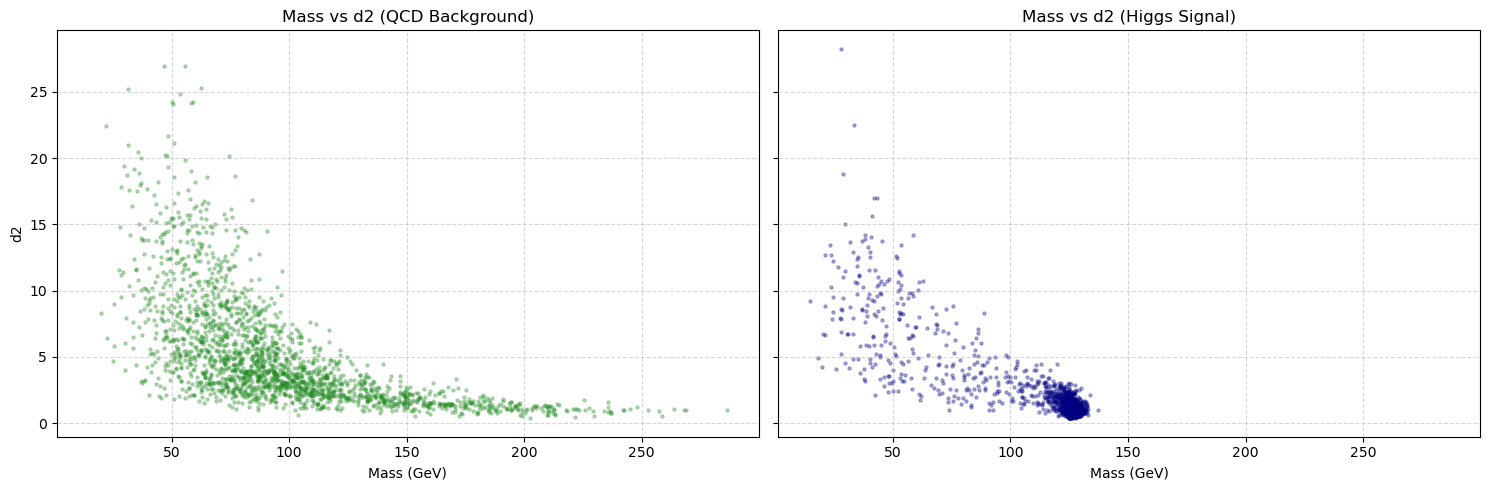

In [25]:
# Generating scatter plots
fig, ax = plt.subplots(1, 2, figsize=(15, 5), sharex=True, sharey=True)

# Sampling 2k events from each so scatter plot loads properly
qcd_sample = qcd_df.sample(2000, random_state=42)
higgs_sample = higgs_df.sample(2000, random_state=42)

# Plotting QCD Background
ax[0].scatter(qcd_sample['mass'], qcd_sample['d2'], alpha=0.3, color='forestgreen', s=5)
ax[0].set_title('Mass vs d2 (QCD Background)')
ax[0].set_xlabel('Mass (GeV)')
ax[0].set_ylabel('d2')
ax[0].grid(True, linestyle='--', alpha=0.5)

# Plotting Higgs Signal
ax[1].scatter(higgs_sample['mass'], higgs_sample['d2'], alpha=0.3, color='navy', s=5)
ax[1].set_title('Mass vs d2 (Higgs Signal)')
ax[1].set_xlabel('Mass (GeV)')
ax[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()